<a href="https://colab.research.google.com/github/eaedk/Machine-Learning-Tutorials-Updated/blob/main/04_nlp/05_text_generation_tiny_gpt.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ✍️ Application · Text generation: train your own tiny GPT on West African folk tales

*"Once upon a time, Anansi the spider wanted all the stories of the world to be his…"*

ChatGPT, Gemini, Llama, all large language models (LLMs) are trained on one single, humble task:
**predict the next token**. In this notebook you will build a GPT **from scratch** (about 100 lines of PyTorch), train
it in a few minutes on your laptop, and watch it go from random gibberish to inventing its own spider tales.

**A 110-year-old idea.**
- **1913** · Andrey Markov counts vowel/consonant sequences in Pushkin's *Eugene Onegin*: the first "language model".
- **1948** · Information theorist C. E. Shannon generates English-looking text by sampling letters and words from **n-gram** statistics.
- **1990s-2015** · Recurrent neural networks (RNN, LSTM) read text one character at a time; Andrej Karpathy's
  *char-rnn* (2015) writes fake Shakespeare and Linux code.
- **2017** · *"Attention Is All You Need"*: the **Transformer** lets every position look at all previous ones at once.
- **2018-today** · OpenAI's **GPT** (*Generative Pre-trained Transformer*) scales it up; GPT-3 (2020) has 175 billion
  parameters, ChatGPT (2022) makes it famous. Our model will have ~2 million, trained on half a megabyte.

**Our corpus.** Two public-domain collections from Project Gutenberg: *West African Folk-Tales* (W. H. Barker &
C. Sinclair, 1917, Gold Coast/Ghana: Anansi stories) and *Cunnie Rabbit, Mr. Spider and the Other Beef* (F. Cronise &
H. Ward, 1903, Sierra Leone). ⚠️ These are colonial-era retellings by European authors, with the vocabulary and biases
of their time. A model trained on them reproduces those biases, an important lesson about LLMs in general.

| Step | Concept |
|---|---|
| 1. Data | characters as tokens, train/validation split |
| 2. Bigram baseline | counting, cross-entropy, perplexity |
| 3. The Transformer | embeddings, self-attention, causal mask, MLP, residuals |
| 4. Training | next-token prediction, learning curves |
| 5. Sampling | temperature, creativity vs coherence |
| 6. Under the hood | what attention looks at |

⏱️ ~5 minutes on a laptop GPU, ~15 on CPU (reduce `MAX_ITERS`).

In [1]:
# ⚙️ Setup: run me first! Finds the course toolkit `mlquest` (Windows, macOS, Linux and Colab).
import os, sys, subprocess, pathlib
if "google.colab" in sys.modules:  # on Colab: grab the repo (once) and the few missing packages
    if not pathlib.Path("/content/Machine-Learning-Tutorials-Updated").exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/eaedk/Machine-Learning-Tutorials-Updated", "/content/Machine-Learning-Tutorials-Updated"], check=True)
    os.chdir("/content/Machine-Learning-Tutorials-Updated")
ROOT = pathlib.Path.cwd()
while not (ROOT / "mlquest").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from mlquest import *  # paths, seed_everything, get_device, quest/checkpoint, Leaderboard...
set_style()
SEED = seed_everything(42)

In [2]:
import math
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

quest("Train your own tiny GPT", chapter="Track 4 · NLP · Text generation", xp=250)
DEVICE = get_device()

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
🗺️  QUEST · Train your own tiny GPT
   Track 4 · NLP · Text generation
   Reward: up to 250 XP
   You are: 🥚 Curious Rookie   ░░░░░░░░░░░░░░░░░░░░░░░░ 0/100 XP
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
⚙️  Using device: mps  (Apple Silicon GPU (Metal))


## 1. The corpus 📚

We download the plain-text books (from Gutenberg mirrors, with a fallback), and cut Gutenberg's licence header and
footer.

In [3]:
BOOKS = {  # Gutenberg id → path on the mirrors
    "West African Folk-Tales (1917)": "6/6/9/2/66923/66923-0.txt",
    "Cunnie Rabbit, Mr. Spider and the Other Beef (1903)": "4/8/8/2/48828/48828-0.txt",
}
MIRRORS = ["https://gutenberg.pglaf.org/", "https://mirrors.xmission.com/gutenberg/", "https://www.gutenberg.org/files/"]

def get_book(path):
    for mirror in MIRRORS:
        url = mirror + path if "files" not in mirror else mirror + "/".join(path.split("/")[-2:])
        try:
            local = download(url, DATA_DIR / "gutenberg" / path.split("/")[-1])
            text = local.read_text(encoding="utf-8")
            if "*** START OF" in text:
                return text.split("*** START OF")[1].split("***", 1)[1].split("*** END OF")[0]
            local.unlink()   # not the book (e.g. a maintenance page): forget it and try the next mirror
        except Exception as e:
            print("mirror failed:", mirror, type(e).__name__)
    return None

texts = [get_book(p) for p in BOOKS.values()]
if not all(texts):   # fallback: Shakespeare, the classic of char-level models
    texts = [download("https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt",
                      DATA_DIR / "gutenberg" / "tinyshakespeare.txt").read_text(encoding="utf-8")]

def clean(t):
    t = t.replace("\r", "").replace("’", "'").replace("‘", "'").replace("“", '"').replace("”", '"').replace("—", "-")
    t = re.sub(r"\[Illustration[^\]]*\]", "", t)
    t = re.sub(r"\n{3,}", "\n\n", t)
    return t.strip()

text = "\n\n".join(clean(t) for t in texts)
print(f"{len(text):,} characters")
start = text.find("In the olden days")          # the first tale
print(text[start:start + 600])

451,594 characters
In the olden days all the stories which men told were stories of
Nyankupon, the chief of the gods. Spider, who was very conceited,
wanted the stories to be told about him.

Accordingly, one day he went to Nyankupon and asked that, in future,
all tales told by men might be Anansi stories, instead of Nyankupon
stories. Nyankupon agreed, on one condition. He told Spider (or Anansi)
that he must bring him three things: the first was a jar full of live
bees, the second was a boa-constrictor, and the third a tiger. Spider
gave his promise.

He took an earthen vessel and set out for a place where he 


### Characters as tokens
Real LLMs use sub-word tokens (~50 000-200 000 of them). To keep things tiny and transparent, our tokens are
**characters**: the vocabulary is every distinct character in the corpus.

In [4]:
chars = sorted(set(text))
VOCAB = len(chars)
stoi = {c: i for i, c in enumerate(chars)}
itos = {i: c for c, i in stoi.items()}
encode = lambda s: [stoi[c] for c in s if c in stoi]
decode = lambda ids: "".join(itos[i] for i in ids)
print(f"Vocabulary: {VOCAB} characters → {''.join(chars)!r}")
print(encode("Anansi"), "→", decode(encode("Anansi")))

data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))
train_data, val_data = data[:n], data[n:]          # the last 10% of the text is the validation set

Vocabulary: 94 characters → '\n !"&\'()*,-.0123456789:;?ABCDEFGHIJKLMNOPQRSTUVWXYZ[]_abcdefghijklmnopqrstuvwxyz£ÁáäéôāēĩōœŪū–'
[25, 67, 54, 67, 72, 62] → Anansi


## 2. Baseline: the bigram model (Markov's idea) 🎲

Predict the next character from the current one only, using counts: after `q` comes `u`, after `.` comes a space…

**How do we score a language model?** With the **cross-entropy loss**: the average of `−log(probability given to the
true next character)`. Lower is better. A model guessing uniformly among the 80-ish characters scores
`log(VOCAB)`. **Perplexity** = `exp(loss)` reads as "the model hesitates between *that many* characters on average".

In [5]:
counts = torch.ones(VOCAB, VOCAB)                   # +1 smoothing: never assign probability 0
for a, b in zip(train_data[:-1].tolist(), train_data[1:].tolist()):
    counts[a, b] += 1
bigram_probs = counts / counts.sum(1, keepdim=True)

val_loss_bigram = -torch.log(bigram_probs[val_data[:-1], val_data[1:]]).mean().item()
lb = Leaderboard("tiny_gpt", metric="val_loss", higher_is_better=False)
lb.add("Uniform guess", math.log(VOCAB), perplexity=round(VOCAB, 1))
lb.add("Bigram counts (Markov)", val_loss_bigram, perplexity=round(math.exp(val_loss_bigram), 1))

g = torch.Generator().manual_seed(SEED)
ids = [stoi["T"]]
for _ in range(300):
    ids.append(torch.multinomial(bigram_probs[ids[-1]], 1, generator=g).item())
print(decode(ids))

📋 Uniform guess: val_loss = 4.54329
📋 Bigram counts (Markov): val_loss = 2.54556  👑 new best!
T Kictinequng, r pin ve ory Y; we ndy  in sidentun.Kideily  f ' b,  k a pl  t.Racappjacis hity coryon nt  h iglsw aree iad
ofr sisifus'. thecouh pldondof or antese hanored rpahengiono TH] C"dole bury, we ton co thema
w _rinameststheawevie ponigheyit de t

 tispst onowidexpize cuporegothive by, shthbb


It has the "texture" of English (short words, spaces, punctuation) but no words. One character of memory is not
enough. We need a model that can look **far back**: the Transformer.

In [6]:
checkpoint("tiny_gpt/bigram", xp=30)

✅ Checkpoint · tiny_gpt/bigram (+30 XP)
   ███████░░░░░░░░░░░░░░░░░ 30/100 XP


## 3. The Transformer, piece by piece 🧱

```
 "Anansi wa"  →  token embeddings + position embeddings
                       │
          ┌────────────▼─────────────┐
          │  masked self-attention   │  each character looks at the previous ones and gathers what it needs
          │  + residual + LayerNorm  │
          │  MLP (feed-forward)      │  then "thinks" about it on its own
          │  + residual + LayerNorm  │
          └────────────┬─────────────┘  × N_LAYER blocks
                       ▼
          linear layer → scores for each of the VOCAB characters → softmax → "n" (next char of "wanted")
```

**Self-attention** in one sentence: each position builds a *query* ("what am I looking for?"), each previous
position offers a *key* ("what do I contain?") and a *value* ("what I give if chosen"); the query-key match decides
how much of each value to take. The **causal mask** forbids looking at the future (otherwise predicting the next
character would be cheating). Several **heads** run in parallel, each free to look for different patterns.

In [7]:
BLOCK_SIZE = 128   # context: how many previous characters the model can see
N_EMBD, N_HEAD, N_LAYER, DROPOUT = 192, 4, 4, 0.1

class CausalSelfAttention(nn.Module):
    def __init__(self):
        super().__init__()
        self.qkv = nn.Linear(N_EMBD, 3 * N_EMBD)
        self.proj = nn.Linear(N_EMBD, N_EMBD)
        self.drop = nn.Dropout(DROPOUT)
        self.register_buffer("mask", torch.tril(torch.ones(BLOCK_SIZE, BLOCK_SIZE)).bool())
        self.last_attention = None      # kept for visualisation

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=2)
        # split into heads: (B, heads, T, head_size)
        q, k, v = (t.view(B, T, N_HEAD, C // N_HEAD).transpose(1, 2) for t in (q, k, v))
        att = (q @ k.transpose(-2, -1)) / math.sqrt(C // N_HEAD)        # how well each query matches each key
        att = att.masked_fill(~self.mask[:T, :T], float("-inf"))        # no peeking at the future
        att = F.softmax(att, dim=-1)
        self.last_attention = att.detach()
        y = self.drop(att) @ v                                            # weighted mix of the values
        return self.proj(y.transpose(1, 2).reshape(B, T, C))

class Block(nn.Module):
    def __init__(self):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(N_EMBD), nn.LayerNorm(N_EMBD)
        self.attn = CausalSelfAttention()
        self.mlp = nn.Sequential(nn.Linear(N_EMBD, 4 * N_EMBD), nn.GELU(), nn.Linear(4 * N_EMBD, N_EMBD), nn.Dropout(DROPOUT))

    def forward(self, x):
        x = x + self.attn(self.ln1(x))   # residual connections: information flows straight through
        return x + self.mlp(self.ln2(x))

class TinyGPT(nn.Module):
    def __init__(self):
        super().__init__()
        self.tok_emb = nn.Embedding(VOCAB, N_EMBD)
        self.pos_emb = nn.Embedding(BLOCK_SIZE, N_EMBD)
        self.blocks = nn.Sequential(*[Block() for _ in range(N_LAYER)])
        self.ln_f = nn.LayerNorm(N_EMBD)
        self.head = nn.Linear(N_EMBD, VOCAB)

    def forward(self, idx, targets=None):
        T = idx.shape[1]
        x = self.tok_emb(idx) + self.pos_emb(torch.arange(T, device=idx.device))
        logits = self.head(self.ln_f(self.blocks(x)))
        loss = None if targets is None else F.cross_entropy(logits.view(-1, VOCAB), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None):
        for _ in range(max_new_tokens):
            logits, _ = self(idx[:, -BLOCK_SIZE:])
            logits = logits[:, -1, :] / temperature
            if top_k:
                v, _ = torch.topk(logits, top_k)
                logits[logits < v[:, [-1]]] = -float("inf")
            idx = torch.cat([idx, torch.multinomial(F.softmax(logits, dim=-1), 1)], dim=1)
        return idx

model = TinyGPT().to(DEVICE)
print(f"TinyGPT: {sum(p.numel() for p in model.parameters()) / 1e6:.2f}M parameters")

def sample(prompt="Once upon a time", n=300, temperature=0.8, top_k=None, seed=SEED):
    torch.manual_seed(seed)
    model.eval()
    idx = torch.tensor([encode(prompt)], device=DEVICE)
    out = decode(model.generate(idx, n, temperature, top_k)[0].tolist())
    model.train()
    return out

print("Before training:\n", sample(n=200))

TinyGPT: 1.84M parameters


Before training:
 Once upon a timez:EmūzÁm"£ndqWjOS kKi!ÁNi enĩL;e3EtY4BäODiorĩél6o£3pTyIilVá?X6])SW(9 £Gx8oPbl&ij6TkÁFQwāGŪ–DJhIiDmmqE:a6Uw(-8)Dwé3Cáūô.ytPDLIMG1AO8(tôœVi5"pā8]p&œ:K5_LWéHMdH.OŪFXv&HH(QNfp.aqĩséĩzc5ēR5FX.fj0aH&á0!E7ēŪ


## 4. Training: millions of "guess the next character" exercises 🏋️

Each step: take a batch of random 128-character windows, ask the model to predict every next character, measure the
loss, and update the weights with the **AdamW** optimiser. We regularly estimate the loss on train and validation
data: if validation stops improving while train keeps going down, the model is **overfitting** (memorising the books).

In [8]:
BATCH_SIZE, MAX_ITERS, EVAL_EVERY, LR = 64, 3000, 250, 1e-3

def get_batch(split):
    src = train_data if split == "train" else val_data
    ix = torch.randint(len(src) - BLOCK_SIZE - 1, (BATCH_SIZE,))
    x = torch.stack([src[i:i + BLOCK_SIZE] for i in ix])
    y = torch.stack([src[i + 1:i + BLOCK_SIZE + 1] for i in ix])
    return x.to(DEVICE), y.to(DEVICE)

@torch.no_grad()
def estimate_loss(iters=40):
    model.eval()
    out = {s: np.mean([model(*get_batch(s))[1].item() for _ in range(iters)]) for s in ("train", "val")}
    model.train()
    return out

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.1)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=LR, total_steps=MAX_ITERS, pct_start=0.1)
history = []
torch.manual_seed(SEED)
for it in range(MAX_ITERS + 1):
    if it % EVAL_EVERY == 0:
        losses = estimate_loss()
        history.append({"iter": it, **losses})
        print(f"iter {it:5d} | train loss {losses['train']:.3f} | val loss {losses['val']:.3f}")
        if it in (500, 1500):
            print("   ✍️ ", sample(n=120).replace("\n", " "))
    if it == MAX_ITERS:
        break
    _, loss = model(*get_batch("train"))
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step(); scheduler.step()

iter     0 | train loss 4.727 | val loss 4.722


iter   250 | train loss 2.407 | val loss 2.386


iter   500 | train loss 1.780 | val loss 1.767


   ✍️  Once upon a time, baing "ded de duh in. Spider the man de one lege ply alone to he day say: 'Mammy:  "'Lan' fus', my day w'en duh reek.'


iter   750 | train loss 1.527 | val loss 1.567


iter  1000 | train loss 1.402 | val loss 1.476


... (5 outputs left out)

iter  2250 | train loss 1.125 | val loss 1.366


iter  2500 | train loss 1.102 | val loss 1.361


iter  2750 | train loss 1.096 | val loss 1.349


iter  3000 | train loss 1.100 | val loss 1.351


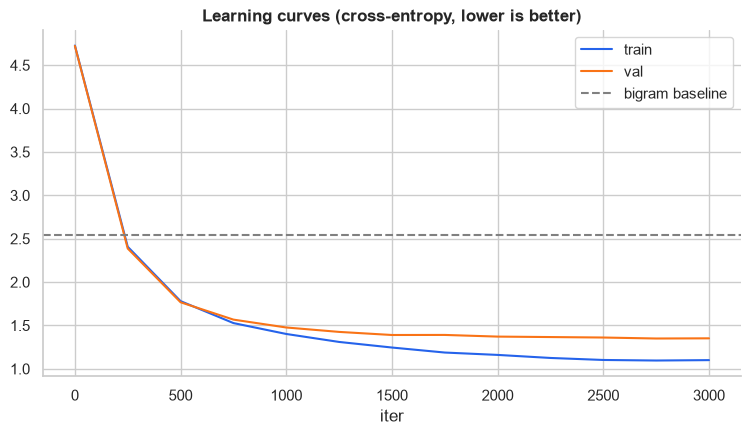

📋 TinyGPT (4 layers, 128 chars of context): val_loss = 1.35018  👑 new best!


In [9]:
h = pd.DataFrame(history)
ax = h.plot(x="iter", y=["train", "val"], title="Learning curves (cross-entropy, lower is better)")
ax.axhline(val_loss_bigram, ls="--", c="grey", label="bigram baseline"); ax.legend(); plt.show()

final = estimate_loss(iters=200)
lb.add("TinyGPT (4 layers, 128 chars of context)", final["val"], perplexity=round(math.exp(final["val"]), 1))
lb.show()
torch.save(model.state_dict(), RUNS_DIR / "tiny_gpt_folktales.pt")

In [10]:
checkpoint("tiny_gpt/trained", xp=80, msg="Your GPT can write!")

✅ Checkpoint · tiny_gpt/trained (+80 XP) Your GPT can write!
🎉 LEVEL UP! You are now 🐣 Data Explorer
   █░░░░░░░░░░░░░░░░░░░░░░░ 110/300 XP


From a perplexity of ~94 (random guess among 94 characters) to the bigram's ~13, then to about 4: the model now
hesitates between only a handful of characters at each step. Notice the gap opening between train and validation
loss in the last iterations: with only 450 000 characters to learn from, the model starts to memorise the books
(**overfitting**); more data or more dropout would be the cure. It has learnt spelling, words, punctuation, dialogue quotes, and the
names of the characters.

## 5. Sampling: the temperature knob 🌡️

At each step the model gives a probability for each character; we **sample** from it. Dividing the scores by a
**temperature** before the softmax changes the style:
- **low** temperature (0.3) → always the most likely characters: safe, repetitive;
- **1.0** → the model's true distribution;
- **high** temperature (1.5) → flatter distribution: creative… then chaotic.

LLM APIs expose exactly this `temperature` parameter.

In [11]:
for t in [0.3, 0.8, 1.5]:
    print(f"━━━ temperature {t} ━━━")
    print(sample("Anansi said to his wife", n=350, temperature=t), "\n")

━━━ temperature 0.3 ━━━


Anansi said to his wife him to the people of the story was
on the remarked the long of the story of the resting of the story of
the farmer of the story of the darkness of the story. The others were
stories, and the spoke of the stories of the story of the story of the
tree who had been some time the same of the story was a story at the
remained to any one the chief. The  

━━━ temperature 0.8 ━━━


Anansi said to his wife, but seven
the farm, and an energy in the remarked chail ness are died. The
time people of the where he would be rook. The transforts him the palm-tree
in little. He people is all the glimb. The air third. He curled her can to
coal and that that they were eagerly gave and stranger distance, is a
great frightful wife, he they did not at time to the 

━━━ temperature 1.5 ━━━


Anansi said to his wife, baizemy not juju King old rome
kind freeore. To weld it not the gratisforbation preparal quastime.

To wa-8 Pulrr oc. SPIDING
A dOt wais' fi]h case Lepped boilivor."
Nexorrise, crownd limined his sons, and did her proin than to sing,
at up that will were eagerbrunatity! Dom promised throughi1] Palm-occasion:

"Dis bril' goy to-day mah, in but yas 



In [12]:
print(sample("Once upon a time, Cunnie Rabbit", n=600, temperature=0.8, top_k=20, seed=7))

Once upon a time, Cunnie Rabbit tell
de cow where the and went over themselves, that personal he powers and stone
himself. When they began to the people to chorus, these many of the folk-lock
no settlemn in the horro faller and well next that he noised.

To part the deer was the began to the matter and his hole with the
followed.

His and chance house thought the story came to him they have their
dest been second inspirers ceasing and lost died. The woman
reason was terrible given that he had gone on the great distress of
being modiffered to the mark of a story through the story could him.

He was not to walked to see this 


## 6. Under the hood: what does attention look at? 🔬

For a prompt, we plot the attention weights of the heads of the **last layer**: row = the position making a
prediction, column = the earlier position it looks at. Bright = strong attention.

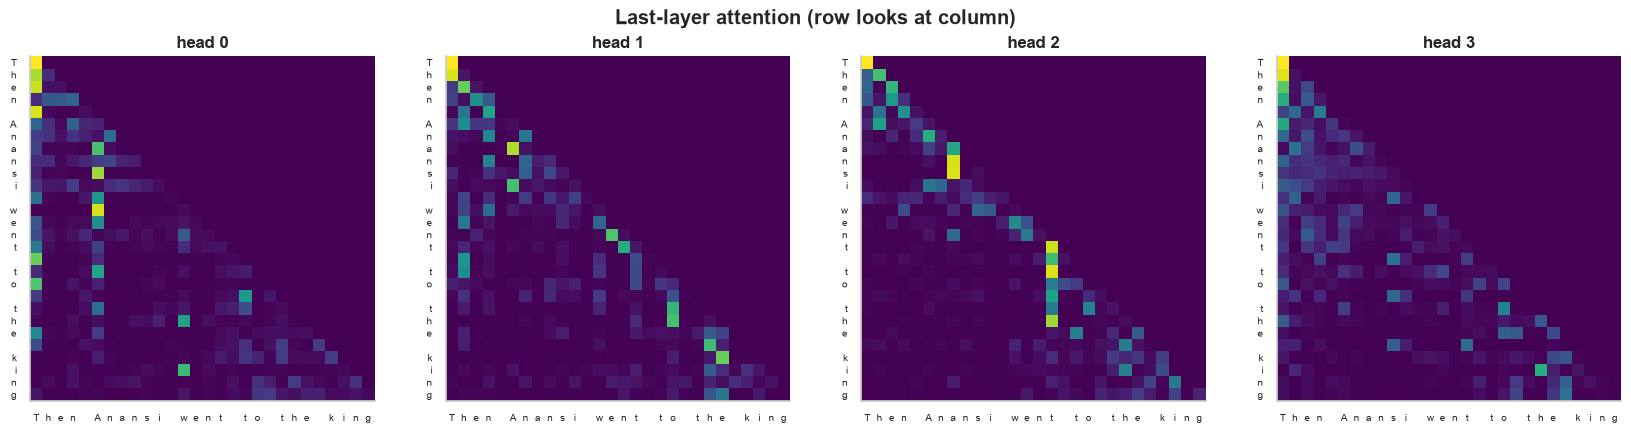

In [13]:
prompt = "Then Anansi went to the king"
model.eval()
with torch.no_grad():
    model(torch.tensor([encode(prompt)], device=DEVICE))
att = model.blocks[-1].attn.last_attention[0].cpu().numpy()      # (heads, T, T)
fig, axes = plt.subplots(1, N_HEAD, figsize=(4.2 * N_HEAD, 4.2))
for h_i, ax in enumerate(axes):
    ax.imshow(att[h_i], cmap="viridis")
    ax.set_xticks(range(len(prompt))); ax.set_xticklabels(list(prompt), fontsize=7)
    ax.set_yticks(range(len(prompt))); ax.set_yticklabels(list(prompt), fontsize=7)
    ax.set_title(f"head {h_i}"); ax.grid(False)
plt.suptitle("Last-layer attention (row looks at column)", fontweight="bold"); plt.tight_layout(); plt.show()

Every map is lower-triangular: that's the causal mask, no peeking at the future. Some heads mostly look at the last
few characters (useful for spelling), others jump back to a few specific earlier characters inside the current or
previous word. Several heads also park a lot of attention on the very **first** character: an "attention sink", a
resting place when there is nothing useful to look at, observed in huge LLMs too. Large models have thousands of
heads with similarly specialised roles.

## 🏆 Quest complete!

You trained a generative transformer from scratch. The difference with ChatGPT is mostly **scale** (data,
parameters, compute), **sub-word tokens**, and an extra phase of **instruction tuning** with human feedback.

### 🚀 Your turn (bonus XP)
1. Train on your own text: song lyrics you wrote, a public-domain book in your language, your class notes…
2. Double `N_LAYER` or `N_EMBD`. Does the validation loss improve, or does the model start to overfit (train ≪ val)?
3. Reduce `BLOCK_SIZE` to 8. What happens to the quality, and why?
4. Replace characters by words or sub-words (hint: `tokenizer = AutoTokenizer.from_pretrained("gpt2")`).

In [14]:
checkpoint("tiny_gpt/complete", xp=140)
badge("Storyteller Engineer", "✍️")
progress()

✅ Checkpoint · tiny_gpt/complete (+140 XP)
   ██████████████████░░░░░░ 250/300 XP
╔══════════════════════════════════════════╗
║ ✍️  BADGE UNLOCKED: Storyteller Engineer ║
╚══════════════════════════════════════════╝
🐣 Data Explorer
██████████████████░░░░░░ 250/300 XP
Checkpoints unlocked: 3
Badges: ✍️ Storyteller Engineer
